<a href="https://colab.research.google.com/github/HamzaEric/online_retail_data_analytics/blob/main/Notebooks/exploratory_Charts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [2]:
df = pd.read_parquet("/content/drive/MyDrive/online_retail_data/retail-lines.parquet")
print(df.shape)
df.head(3)

(1033036, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0


# Product Lines

In retail datasets (like the standard Online Retail dataset), real products have 5-digit numeric codes, while non-product entries (like postage, discounts, or manual fees) use text codes.

In [5]:
is_product = df['StockCode'].str.match(r"\d{5}")
sales = df[is_product]

print(f"product lines:     {len(sales):,}")
print(f"non-product lines: {(~is_product).sum():,}")
df.loc[~is_product, "StockCode"].value_counts().head(6)

product lines:     1,027,056
non-product lines: 5,980


,count
StockCode,
POST,2086
DOT,1425
M,1387
C2,277
D,173
S,101


> 📊 **Reading the counts.** **1,027,056** product lines kept and **5,980** set aside — mostly
> postage (`POST`), `DOT` (another postage code) and manual adjustments (`M`), then a few
> other codes such as carriage (`C2`), discounts (`D`) and samples (`S`).

What does netting do to the totals? The cancellation lines stay in `sales`, with negative
revenue.

In [6]:
is_cancel = sales["Invoice"].str.startswith("C")
print(f"cancellation lines among products: {is_cancel.sum():,}")
print(f"net sales (cancellations subtracted): £{sales['Revenue'].sum() / 1e6:.2f}M")
print(f"sales if cancellations were ignored:  £{sales.loc[~is_cancel, 'Revenue'].sum() / 1e6:.2f}M")

cancellation lines among products: 17,914
net sales (cancellations subtracted): £18.93M
sales if cancellations were ignored:  £19.64M


In [7]:
birdie = sales[sales["Description"] == "PAPER CRAFT , LITTLE BIRDIE"]
birdie[["Invoice", "InvoiceDate", "Quantity", "Price", "Revenue"]]

,Invoice,InvoiceDate,Quantity,Price,Revenue
1065882,581483,2011-12-09 09:15:00,80995,2.08,168469.6
1065883,C581484,2011-12-09 09:27:00,-80995,2.08,-168469.6


> 📊 **Reading the difference.** **17,914** cancellation lines. Netted, two years of product
> sales come to **`£18.93M`**; ignoring the cancellations would claim **`£19.64M`** — about
> `£0.7M` of goods that were ordered and then undone. The single product shows why it matters:
> an order of **80,995** paper-craft birds (`£168,470`) on 9 December 2011 and, twelve minutes
> later, its cancellation (`C581484`, −80,995). Netted, the product's total is `£0`. Ignoring the cancellation, it would
> rank among the shop's best sellers.

In [8]:
monthly_sales = sales.set_index("InvoiceDate")["Revenue"].resample("ME").sum() / 1000
month_labels = monthly_sales.index.strftime("%b %Y")

print(list(month_labels[:3]), "...", list(month_labels[-2:]))
monthly_sales.round(0).loc["2010-10":"2010-12"]

['Dec 2009', 'Jan 2010', 'Feb 2010'] ... ['Nov 2011', 'Dec 2011']


,Revenue
InvoiceDate,
2010-10-31,1069.0
2010-11-30,1394.0
2010-12-31,758.0


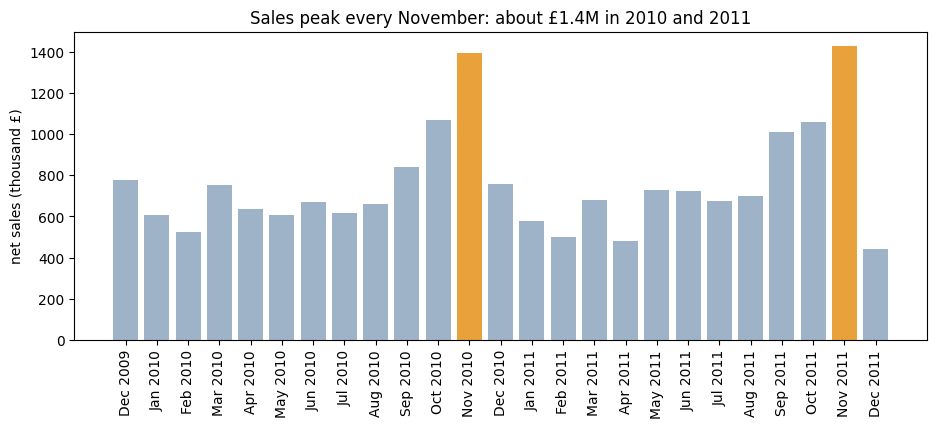

In [9]:
colors = ["#e9a13b" if month in [11] else "#9fb3c8" for month in monthly_sales.index.month]

fig_sales, ax_sales = plt.subplots(figsize=(11, 4))
ax_sales.bar(month_labels, monthly_sales.values, color=colors)
ax_sales.set_title("Sales peak every November: about £1.4M in 2010 and 2011")
ax_sales.set_ylabel("net sales (thousand £)")
ax_sales.tick_params(axis="x", rotation=90)
plt.show()

> 📊 **Reading the chart.** The title says the finding, the axis says the unit, and the two
> amber bars make the title checkable at a glance: November 2010 and November 2011, both about
> `£1.4M`. The gray bars are still there — context — but they no longer compete for attention.

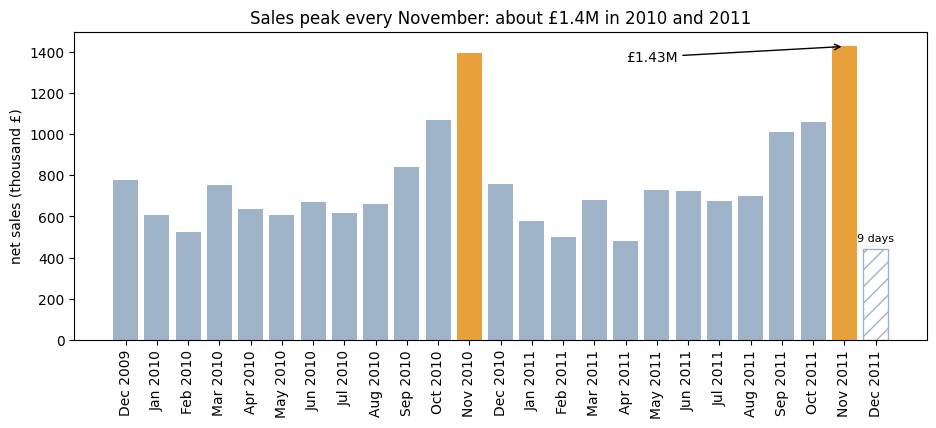

In [10]:
peak_position = monthly_sales.values.argmax()
peak_value = monthly_sales.max()

ax_sales.annotate(f"£{peak_value / 1000:.2f}M", xy=(peak_position, peak_value),
                  xytext=(peak_position - 7, peak_value * 0.95),
                  arrowprops={"arrowstyle": "->"})

last_bar = ax_sales.patches[-1]
last_bar.set_facecolor("white")
last_bar.set_edgecolor("#9fb3c8")
last_bar.set_hatch("//")
ax_sales.text(len(monthly_sales) - 1, monthly_sales.iloc[-1] + 40, "9 days", ha="center", fontsize=8)
fig_sales

> 📊 **Reading the finished chart.** All five fixes are in place: the title states the finding,
> the axis carries its unit, the bars start at zero, the Novembers are highlighted, the peak
> is annotated (**`£1.43M`**, November 2011) and the hatched last bar is labeled **9 days** — so
> nobody mistakes the end of the data for the end of the business.

# Growth

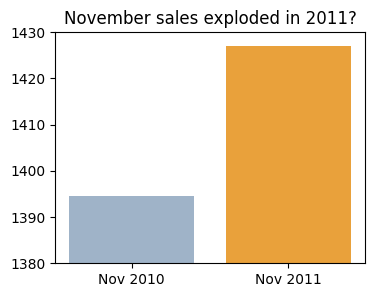

real change: +2.3%


In [11]:
novembers = monthly_sales[monthly_sales.index.month == 11]
labels = ["Nov 2010", "Nov 2011"]

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(labels, novembers.values, color=["#9fb3c8", "#e9a13b"])
ax.set_ylim(1380, 1430)
ax.set_title("November sales exploded in 2011?")
plt.show()
print(f"real change: {novembers.iloc[1] / novembers.iloc[0] - 1:+.1%}")

> 📊 **Reading the trick.** The 2011 bar looks about **three times** taller than 2010's. The
> real change is **+2.3 %** (`£1,394k` → `£1,427k`). The y-axis starts at 1,380, so the bars
> show only their top slivers — and a bar's **length** is exactly what a reader compares.

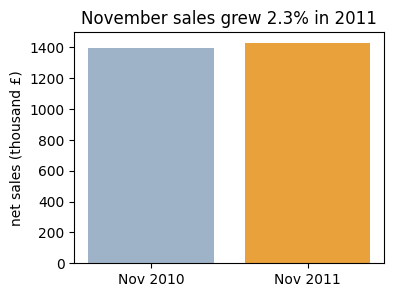

In [12]:
fig_honest, ax_honest = plt.subplots(figsize=(4, 3))
ax_honest.bar(labels, novembers.values, color=["#9fb3c8", "#e9a13b"])
ax_honest.set_ylim(bottom=0)
ax_honest.set_ylabel("net sales (thousand £)")
ax_honest.set_title("November sales grew 2.3% in 2011")
plt.show()

> 📊 **Reading the honest chart.** Two bars of almost the same height — which is the truth:
> November 2011 was slightly better than November 2010. The title says **"grew 2.3%"**, and the
> chart agrees with it.

## Comparing Two Years

In [13]:
by_year = (
    monthly_sales.to_frame("sales")
    .assign(year=lambda d: d.index.year, month=lambda d: d.index.month)
    .pivot(index="month", columns="year", values="sales")
)

by_year.round(0)

year,2009,2010,2011
month,,,
1,NaN,605.0,579.0
2,NaN,525.0,499.0
3,NaN,752.0,679.0
4,NaN,636.0,482.0
5,NaN,606.0,731.0
6,NaN,670.0,724.0
7,NaN,616.0,677.0
8,NaN,662.0,701.0
9,NaN,842.0,1011.0


> 📊 **Reading the table.** Twelve months as rows; 2009 has only December (the data starts on
> 1 December 2009), 2010 is complete, and 2011's December is the nine-day partial month. So the
> fair comparison is **2010 against 2011**, January to November, with December 2011 marked.

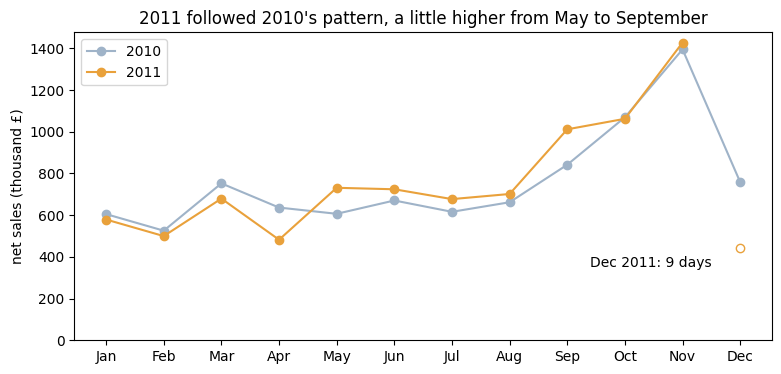

In [14]:
fig_years, ax_years = plt.subplots(figsize=(9, 4))
ax_years.plot(by_year.index, by_year[2010], color="#9fb3c8", marker="o", label="2010")
ax_years.plot(by_year.index[:11], by_year[2011].iloc[:11], color="#e9a13b", marker="o", label="2011")
ax_years.plot(12, by_year.loc[12, 2011], marker="o", markerfacecolor="white", color="#e9a13b")
ax_years.annotate("Dec 2011: 9 days", xy=(12, by_year.loc[12, 2011]), xytext=(9.4, 350))

ax_years.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax_years.set_ylim(bottom=0)
ax_years.set_ylabel("net sales (thousand £)")
ax_years.set_title("2011 followed 2010's pattern, a little higher from May to September")
ax_years.legend()
plt.show()

> 📊 **Reading the overlay.** The two years trace the **same shape**: a quiet first half, a
> steady climb from September, the November peak. 2011 ran a little below 2010 from January to
> April, a little above from May to September, and level with it in October and November. The open marker and its label keep the
> nine-day December from being read as a crash. The legend says which color is which year —
> needed as soon as a chart has more than one line.

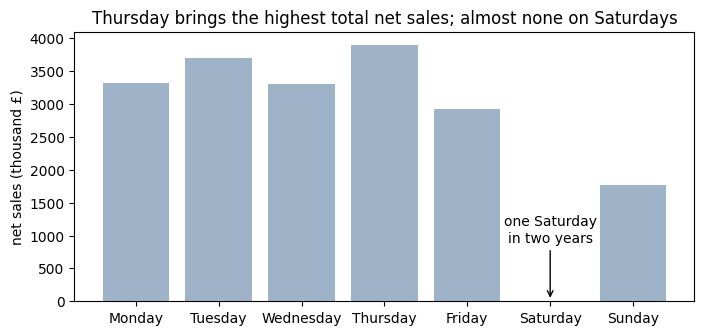

,Revenue
InvoiceDate,
Monday,3316.0
Tuesday,3694.0
Wednesday,3301.0
Thursday,3905.0
Friday,2932.0
Saturday,10.0
Sunday,1768.0


In [15]:
week = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_sales = sales.groupby(sales["InvoiceDate"].dt.day_name())["Revenue"].sum().reindex(week) / 1000

fig_week, ax_week = plt.subplots(figsize=(8, 3.5))
ax_week.bar(weekday_sales.index, weekday_sales.values, color="#9fb3c8")
ax_week.set_ylabel("net sales (thousand £)")
ax_week.set_title("Thursday brings the highest total net sales; almost none on Saturdays")
ax_week.annotate("one Saturday\nin two years", xy=(5, 10), xytext=(5, 900), ha="center",
                 arrowprops={"arrowstyle": "->"})
plt.show()
weekday_sales.round(0)

> 📊 **Reading the week.** Thursday brings the highest **total** net sales (**`£3,905k`** over
> two years), Friday and especially Sunday less (`£2,932k` and `£1,768k`), and Saturday almost
> nothing (`£10k`; recall from Lesson 4.1 that the only Saturday in the data is 5 December
> 2009). The annotation tells the reader *why* the bar is missing, before they wonder whether it
> is an error.

Notice what the title claims: the highest **total**. A total over two years also depends on how
many Thursdays, Mondays and so on the data contains — public holidays, closures and the two
partial months at the ends do not hit every weekday equally. To claim that Thursday is the
busiest **day**, we must divide each total by the number of days it adds up. A **trading day**
here is a calendar date with at least one sale recorded.

In [16]:
trading_dates = sales["InvoiceDate"].dt.normalize().drop_duplicates()
trading_days = trading_dates.dt.day_name().value_counts().reindex(week)

pd.DataFrame({
    "total (thousand £)": weekday_sales.round(0),
    "trading days": trading_days,
    "per trading day (thousand £)": (weekday_sales / trading_days).round(1),
})

,total (thousand £),trading days,per trading day (thousand £)
InvoiceDate,,,
Monday,3316.0,94,35.3
Tuesday,3694.0,104,35.5
Wednesday,3301.0,104,31.7
Thursday,3905.0,103,37.9
Friday,2932.0,99,29.6
Saturday,10.0,1,9.8
Sunday,1768.0,99,17.9


## Top Products

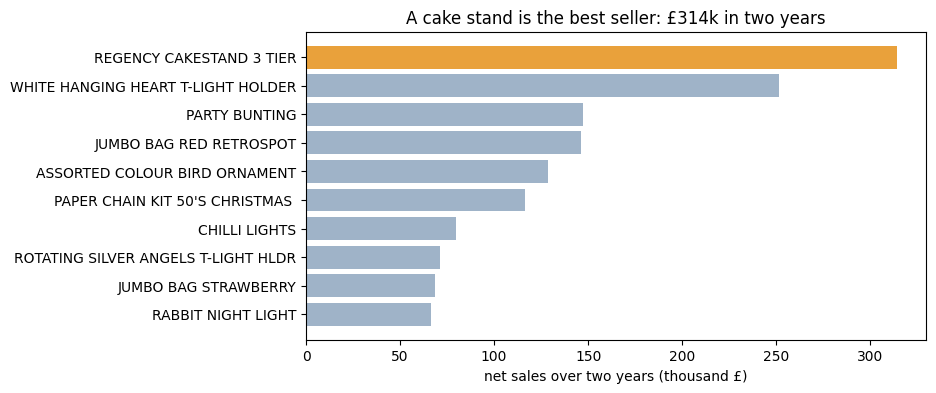

In [17]:
top_products = sales.groupby("Description")["Revenue"].sum().nlargest(10) / 1000

fig_products, ax_products = plt.subplots(figsize=(8, 4))
colors = ["#e9a13b"] + ["#9fb3c8"] * (len(top_products) - 1)
ax_products.barh(top_products.index[::-1], top_products.values[::-1], color=colors[::-1])
ax_products.set_xlabel("net sales over two years (thousand £)")
ax_products.set_title("A cake stand is the best seller: £314k in two years")
plt.show()

# Exports

In [21]:
uk_share = sales.loc[sales["Country"] == "United Kingdom", "Revenue"].sum() / sales["Revenue"].sum()
print(f"UK customers: {uk_share:.1%} of net sales")

UK customers: 85.4% of net sales


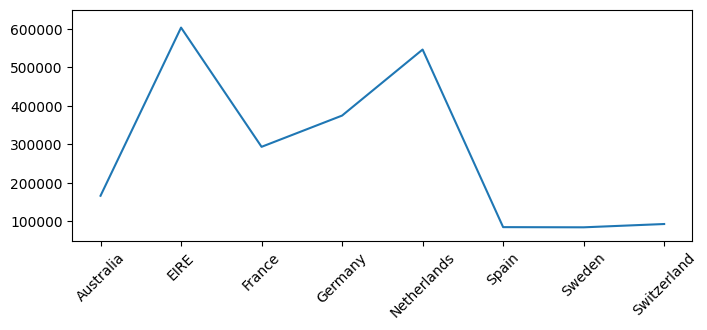

In [19]:
exports = sales[sales["Country"] != "United Kingdom"].groupby("Country")["Revenue"].sum().nlargest(8).sort_index()

fig_weak, ax_weak = plt.subplots(figsize=(8, 3))
ax_weak.plot(exports.index, exports.values)
ax_weak.set_ylim(50000, 650000)
ax_weak.tick_params(axis="x", rotation=45)
plt.show()

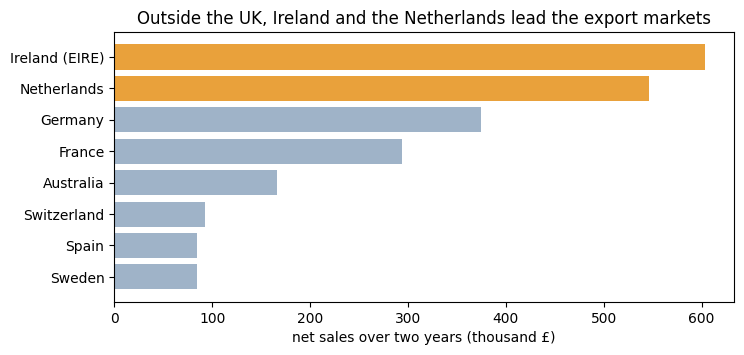

,Revenue
Country,
Sweden,84.3
Spain,84.8
Switzerland,92.9
Australia,166.3
France,293.4
Germany,374.6
Netherlands,546.1
Ireland (EIRE),603.1


In [20]:
export_k = exports.rename(index={"EIRE": "Ireland (EIRE)"}).sort_values() / 1000
colors = ["#9fb3c8"] * (len(export_k) - 2) + ["#e9a13b"] * 2

fig_exports, ax_exports = plt.subplots(figsize=(8, 3.5))
ax_exports.barh(export_k.index, export_k.values, color=colors)
ax_exports.set_xlabel("net sales over two years (thousand £)")
ax_exports.set_title("Outside the UK, Ireland and the Netherlands lead the export markets")
plt.show()
export_k.round(1)

> 📊 **Reading our version.** Ireland (`£603.1k` over two years) and the Netherlands
> (`£546.1k`) are the two amber bars at the top, well ahead of Germany (`£374.6k`) and France
> (`£293.4k`); the four smallest markets are each below `£170k`. The `rename` writes the
> country under its English name, keeping the data's own spelling in brackets.

In [22]:
figures_dir = Path("./figures")
figures_dir.mkdir(exist_ok=True)

print(figures_dir.exists())

True


In [23]:
pack = {
    "monthly-sales": fig_sales,
    "novembers": fig_honest,
    "two-years": fig_years,
    "weekdays": fig_week,
    "top-products": fig_products,
}
for name, fig in pack.items():
    fig.savefig(figures_dir / f"{name}.png", dpi=150, bbox_inches="tight")

sorted(p.name for p in figures_dir.glob("*.png"))

['monthly-sales.png',
 'novembers.png',
 'top-products.png',
 'two-years.png',
 'weekdays.png']